# 06 · Evaluación y comparación de modelos

Evaluación final de todos los modelos sobre el split **`test`** (7,340 filas), que ninguno usó para entrenar ni para ajustar hiperparámetros.

| Modelo | Descripción |
|---|---|
| Línea base | Para cada par (pregunta, respuesta), las 3 etiquetas más frecuentes en train |
| M1 `M1_tfidf_lr` | TF-IDF de palabras y caracteres + regresión logística |
| M2 `M2_sbert_lgbm` | Embeddings Sentence-BERT + LightGBM |
| M3 `M3_deberta` | DeBERTa-v3-base con ajuste fino |

**Métricas:** macro-F1 (principal según los objetivos), precisión y recall macro, exactitud y MAP@3 (métrica del reto), además de métricas por nivel (corrección, `Category` y `Misconception`) y por clase. Los resultados se guardan en `results/metricas/` (la aplicación los reutiliza) y las figuras en `results/figuras/`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

from src import evaluacion as ev
from src import linea_base as lb
from src import paleta
from src import preprocesamiento as pp
from src.utilidades import DIR_RESULTADOS, RUTA_TIEMPOS, guardar_predicciones, registrar_tiempo

DIR_METRICAS = DIR_RESULTADOS / "metricas"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_METRICAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

MODELOS = ["linea_base", "M1_tfidf_lr", "M2_sbert_lgbm", "M3_deberta"]
paleta.aplicar_estilo()
pd.set_option("display.precision", 4)

## 1. Datos y línea base

La línea base solo usa la pregunta y la respuesta elegida, sin leer la explicación. Sirve para medir cuánto aporta realmente el texto del estudiante: como la corrección y las ideas erróneas posibles dependen casi por completo del par (pregunta, respuesta), esta línea base es más fuerte de lo que parece.

In [2]:
df = pp.cargar_train_clean()
datos = pp.aplicar_particion(df)
respuestas, preguntas, _ = pp.cargar_reglas()
train = pp.preparar_dataframe(datos["train"], respuestas, preguntas)
test = pp.preparar_dataframe(datos["test"], respuestas, preguntas)

inicio = time.time()
tabla_lb = lb.ajustar(train)
t_lb_train = time.time() - inicio
inicio = time.time()
pred_lb = lb.predecir(tabla_lb, test)
t_lb_inf = time.time() - inicio

guardar_predicciones(pred_lb, lb.NOMBRE)
registrar_tiempo(lb.NOMBRE, t_lb_train, t_lb_inf, hardware="CPU")
pred_lb.head()

,row_id,top1,top2,top3,prob1,prob2,prob3
0,0,True_Correct:NA,True_Neither:NA,True_Misconception:WNB,0.7297,0.2624,0.0043
1,16,True_Correct:NA,True_Neither:NA,True_Misconception:WNB,0.7297,0.2624,0.0043
2,19,True_Correct:NA,True_Neither:NA,True_Misconception:WNB,0.7297,0.2624,0.0043
3,24,True_Correct:NA,True_Neither:NA,True_Misconception:WNB,0.7297,0.2624,0.0043
4,26,True_Correct:NA,True_Neither:NA,True_Misconception:WNB,0.7297,0.2624,0.0043


In [3]:
# Etiqueta real y variables de contexto para el análisis de errores
test["n_palabras"] = test["StudentExplanation"].astype(str).str.split().str.len()
verdad = test[["row_id", "target", "QuestionId", "MC_Answer_norm", "StudentExplanation",
               "Category", "Misconception", "n_palabras"]]
preds = {m: ev.cargar_predicciones(m, verdad) for m in MODELOS}
{m: len(p) for m, p in preds.items()}

{'linea_base': 7340,
 'M1_tfidf_lr': 7340,
 'M2_sbert_lgbm': 7340,
 'M3_deberta': 7340}

## 2. Métricas globales

Una fila por modelo, con las métricas sobre la etiqueta conjunta (64 clases), las métricas por nivel y los tiempos de `results/tiempos.csv`. La mejora relativa se mide contra la línea base.

In [4]:
tiempos = pd.read_csv(RUTA_TIEMPOS).set_index("modelo")
resumen = pd.DataFrame({m: ev.metricas_resumen(p) for m, p in preds.items()}).T
resumen = resumen.join(tiempos)
resumen.index.name = "modelo"
for col in ["f1_macro", "map_at_3"]:
    resumen[f"mejora_{col}_vs_base"] = resumen[col] - resumen.loc["linea_base", col]
resumen["ms_por_respuesta"] = resumen["tiempo_inferencia_test_s"] / len(test) * 1000
resumen.reset_index().to_csv(DIR_METRICAS / "metricas_resumen.csv", index=False)

cols = ["f1_macro", "precision_macro", "recall_macro", "accuracy", "map_at_3",
        "tiempo_entrenamiento_s", "tiempo_inferencia_test_s"]
resumen[cols]

,f1_macro,precision_macro,recall_macro,accuracy,map_at_3,tiempo_entrenamiento_s,tiempo_inferencia_test_s
modelo,,,,,,,
linea_base,0.2965,0.2568,0.3584,0.6946,0.8388,0.09,0.10
M1_tfidf_lr,0.5573,0.5958,0.5402,0.8475,0.9203,99.81,1.54
M2_sbert_lgbm,0.5284,0.5559,0.5254,0.8262,0.9087,229.22,56.05
M3_deberta,0.5540,0.5234,0.5986,0.8475,0.9185,1665.70,809.53


In [5]:
# Métricas por nivel (macro-F1 / exactitud)
niveles = ["correccion", "category", "misconception"]
resumen[[f"{t}_{n}" for n in niveles for t in ["f1_macro", "accuracy"]]]

,f1_macro_correccion,accuracy_correccion,f1_macro_category,accuracy_category,f1_macro_misconception,accuracy_misconception
modelo,,,,,,
linea_base,1.0,1.0,0.3524,0.7020,0.4962,0.8074
M1_tfidf_lr,1.0,1.0,0.7415,0.8507,0.7597,0.8606
M2_sbert_lgbm,1.0,1.0,0.7188,0.8302,0.7305,0.8652
M3_deberta,1.0,1.0,0.7413,0.8530,0.7738,0.9123


**Conclusión:**
- Los tres modelos superan con claridad a la línea base: macro-F1 de 0.30 → 0.53–0.56 y MAP@3 de 0.84 → 0.91–0.92. Leer la explicación casi duplica el macro-F1; en MAP@3 la mejora es menor porque la línea base ya acierta las clases frecuentes.
- **M1 y M3 quedan empatados** (macro-F1 0.557 vs 0.554, misma exactitud 0.848). M2 queda ~0.03 por debajo.
- La corrección (True/False) es perfecta en todos gracias a la máscara. La diferencia está en el tipo de explicación y en la idea errónea: cuando la respuesta tiene una idea errónea, M3 identifica cuál con 91 % de exactitud, contra 86 % de M1 y M2.
- Todos bajan respecto a validación (M1 0.617 → 0.557, M2 0.589 → 0.528, M3 0.583 → 0.554). El macro-F1 promedia clases con muy pocos ejemplos y es inestable; M3 es el que menos cae.

## 3. Métricas por clase, por pregunta y matrices de confusión

Se guardan en formato largo (una columna `modelo`) para que la aplicación filtre por modelo.

In [6]:
por_clase = pd.concat([ev.metricas_por_clase(p).assign(modelo=m) for m, p in preds.items()], ignore_index=True)
por_clase = por_clase[["modelo", "nivel", "clase", "precision", "recall", "f1", "soporte"]]
por_clase.to_csv(DIR_METRICAS / "metricas_por_clase.csv", index=False)

por_pregunta = pd.concat([ev.metricas_por_grupo(p, "QuestionId").assign(modelo=m) for m, p in preds.items()],
                         ignore_index=True)
por_pregunta.to_csv(DIR_METRICAS / "metricas_por_pregunta.csv", index=False)

CATEGORIAS = list(paleta.COLORES_CATEGORIA)
confusiones = []
for m, p in preds.items():
    cm = ev.matriz_confusion(p["Category"], p["top1"].str.split(":").str[0], CATEGORIAS, normalizar=False)
    larga = cm.stack().rename("n").reset_index()
    larga["proporcion"] = larga["n"] / larga.groupby("real")["n"].transform("sum").replace(0, 1)
    confusiones.append(larga.assign(modelo=m))
pd.concat(confusiones)[["modelo", "real", "predicha", "n", "proporcion"]].to_csv(
    DIR_METRICAS / "confusion_category.csv", index=False)

sorted(p.name for p in DIR_METRICAS.glob("*.csv"))

['confusion_category.csv',
 'metricas_por_clase.csv',
 'metricas_por_pregunta.csv',
 'metricas_resumen.csv']

In [7]:
# F1 por Category: atención a las minoritarias True_Misconception y False_Correct
cat = por_clase[por_clase.nivel == "category"].pivot(index="clase", columns="modelo", values="f1")[MODELOS]
cat["soporte"] = por_clase[(por_clase.nivel == "category") & (por_clase.modelo == "M1_tfidf_lr")].set_index("clase")["soporte"]
cat.sort_values("soporte", ascending=False)

modelo,linea_base,M1_tfidf_lr,M2_sbert_lgbm,M3_deberta,soporte
clase,,,,,
True_Correct,0.8394,0.9038,0.8943,0.9177,2961
False_Misconception,0.7619,0.8807,0.8587,0.8752,1893
False_Neither,0.5130,0.8164,0.7651,0.7698,1308
True_Neither,0.0000,0.7067,0.6956,0.7450,1053
True_Misconception,0.0000,0.5128,0.4878,0.5714,80
False_Correct,0.0000,0.6286,0.6111,0.5686,45


**Conclusión:** en las categorías grandes los tres modelos rinden parecido. En las minoritarias no hay un ganador único: M3 es el mejor en `True_Misconception` (F1 0.57, gracias a su pérdida ponderada) y M1 en `False_Correct` (0.63). La línea base obtiene F1 = 0 en tres categorías porque nunca las pone en primer lugar.

## 4. Selección del modelo final

El criterio principal es el **macro-F1** sobre la etiqueta conjunta, porque los objetivos del proyecto piden identificar también las ideas erróneas poco frecuentes. MAP@3 (métrica del reto) y el costo de inferencia se usan como criterios secundarios.

In [8]:
ranking = resumen.drop(index="linea_base").sort_values(["f1_macro", "map_at_3"], ascending=False)
MEJOR = ranking.index[0]
print("Mejor modelo por macro-F1:", MEJOR)
ranking[["f1_macro", "map_at_3", "accuracy", "tiempo_inferencia_test_s", "ms_por_respuesta"]]

Mejor modelo por macro-F1: M1_tfidf_lr


,f1_macro,map_at_3,accuracy,tiempo_inferencia_test_s,ms_por_respuesta
modelo,,,,,
M1_tfidf_lr,0.5573,0.9203,0.8475,1.54,0.2098
M3_deberta,0.5540,0.9185,0.8475,809.53,110.2902
M2_sbert_lgbm,0.5284,0.9087,0.8262,56.05,7.6362


**Modelo final recomendado: M1 (TF-IDF + regresión logística).**
- Empata con M3 en macro-F1 y exactitud, y tiene el mejor MAP@3 (0.920).
- Es ~500 veces más rápido en inferencia (1.5 s contra 810 s para 7,340 respuestas en CPU; 0.2 ms contra 110 ms por respuesta) y se entrena en ~100 s en CPU, sin GPU.
- Es interpretable (coeficientes por término) y su archivo pesa 8 MB, contra ~740 MB de M3: ideal para la aplicación.

**M3** es la alternativa cuando lo prioritario es identificar la idea errónea concreta (exactitud 0.91 en ese nivel) o el recall de las clases raras (recall macro 0.60 contra 0.54), si se acepta su costo. **M2** no compensa: cuesta más que M1 y rinde menos que ambos.

## 5. Visualizaciones

Todas las figuras usan la paleta de `src/paleta.py` (Okabe–Ito, segura para daltonismo), la misma de la aplicación, y se guardan a 300 dpi.

### Figura 1. Macro-F1 y MAP@3 por modelo

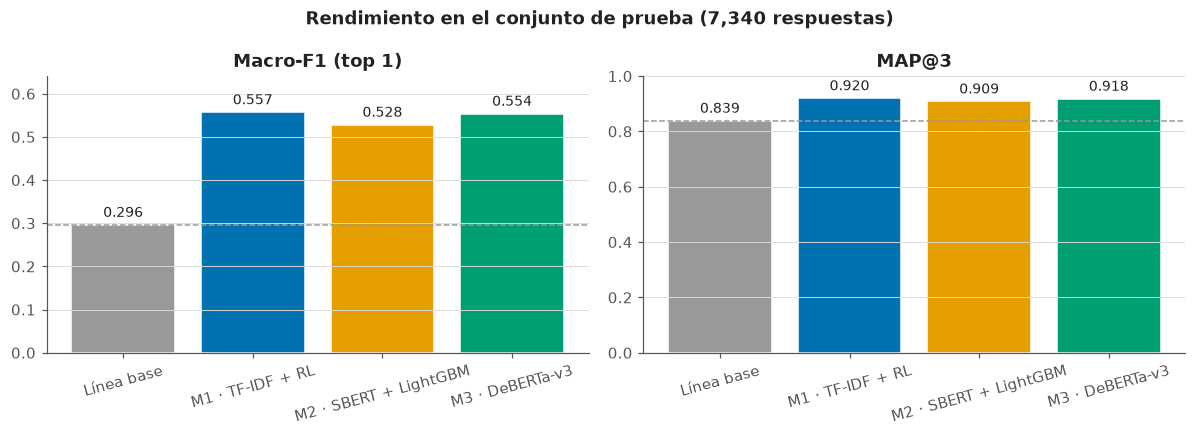

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, (col, titulo) in zip(axes, [("f1_macro", "Macro-F1 (top 1)"), ("map_at_3", "MAP@3")]):
    vals = resumen.loc[MODELOS, col]
    barras = ax.bar([paleta.nombre_modelo(m) for m in MODELOS], vals,
                    color=[paleta.color_modelo(m) for m in MODELOS], edgecolor="white")
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=9)
    ax.axhline(vals["linea_base"], color=paleta.COLORES_MODELO["linea_base"], ls="--", lw=1)
    ax.set_title(titulo)
    ax.set_ylim(0, min(1.0, vals.max() * 1.15))
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="x", visible=False)
fig.suptitle("Rendimiento en el conjunto de prueba (7,340 respuestas)", fontweight="bold")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig1_metricas_por_modelo.png")
plt.show()

**Conclusión:** la mejora sobre la línea base es grande en macro-F1 (≈ +0.26) y moderada en MAP@3 (≈ +0.08). La línea base ya ordena bien las etiquetas frecuentes de cada par pregunta-respuesta, y el valor del texto está en las clases poco frecuentes. Entre modelos las diferencias son pequeñas frente a la distancia con la línea base.

### Figura 2. Matriz de confusión de `Category` (mejor modelo)

Normalizada por fila: cada celda es la proporción de respuestas de la categoría real que el modelo asignó a cada categoría predicha (la diagonal es el recall).

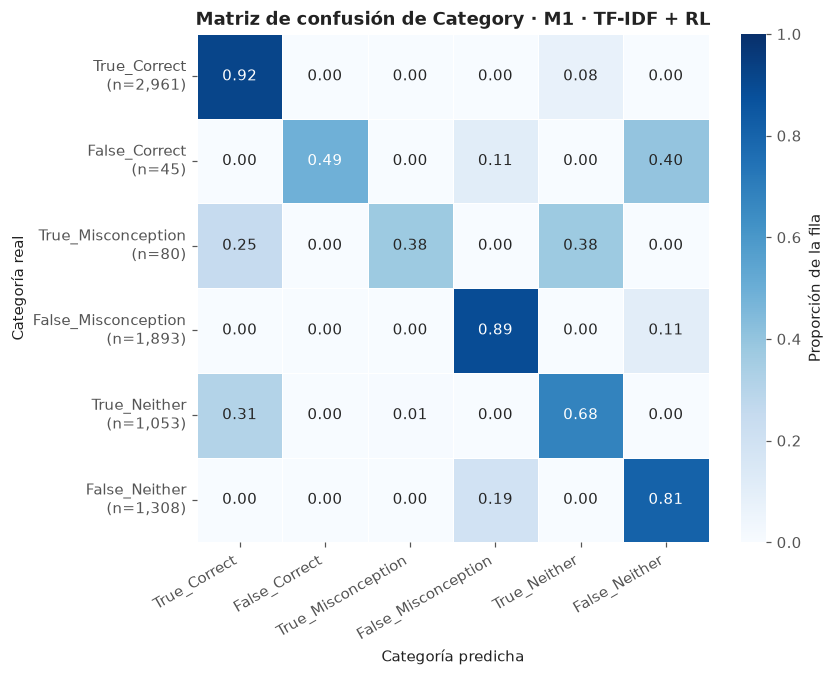

In [10]:
p = preds[MEJOR]
cm = ev.matriz_confusion(p["Category"], p["top1"].str.split(":").str[0], CATEGORIAS)
soporte = p["Category"].value_counts().reindex(CATEGORIAS).fillna(0).astype(int)
etiquetas_y = [f"{c}\n(n={soporte[c]:,})" for c in CATEGORIAS]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap=paleta.MAPA_SECUENCIAL, vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "Proporción de la fila"}, yticklabels=etiquetas_y, linewidths=0.5, linecolor="white")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")
ax.set_title(f"Matriz de confusión de Category · {paleta.nombre_modelo(MEJOR)}")
ax.grid(False)
plt.xticks(rotation=30, ha="right")
fig.savefig(DIR_FIGURAS / "fig2_confusion_category.png")
plt.show()

**Conclusión:** nunca se confunde `True` con `False` (lo garantiza la máscara). El error dominante está en decidir si la explicación es correcta o no aporta (`Neither`): 31 % de `True_Neither` se predice como `True_Correct`, y 40 % de `False_Correct` como `False_Neither`. Las minoritarias son las más difíciles: `True_Misconception` se reparte casi por igual entre las tres categorías `True_*`. Esa frontera entre `Correct` y `Neither` depende del criterio del anotador, lo que limita a cualquier modelo.

### Figura 3. F1 por idea errónea (mejor modelo)

Solo filas cuya etiqueta real tiene idea errónea. Las barras con trama corresponden a ideas erróneas con menos de 20 ejemplos en prueba, donde el F1 es poco estable.

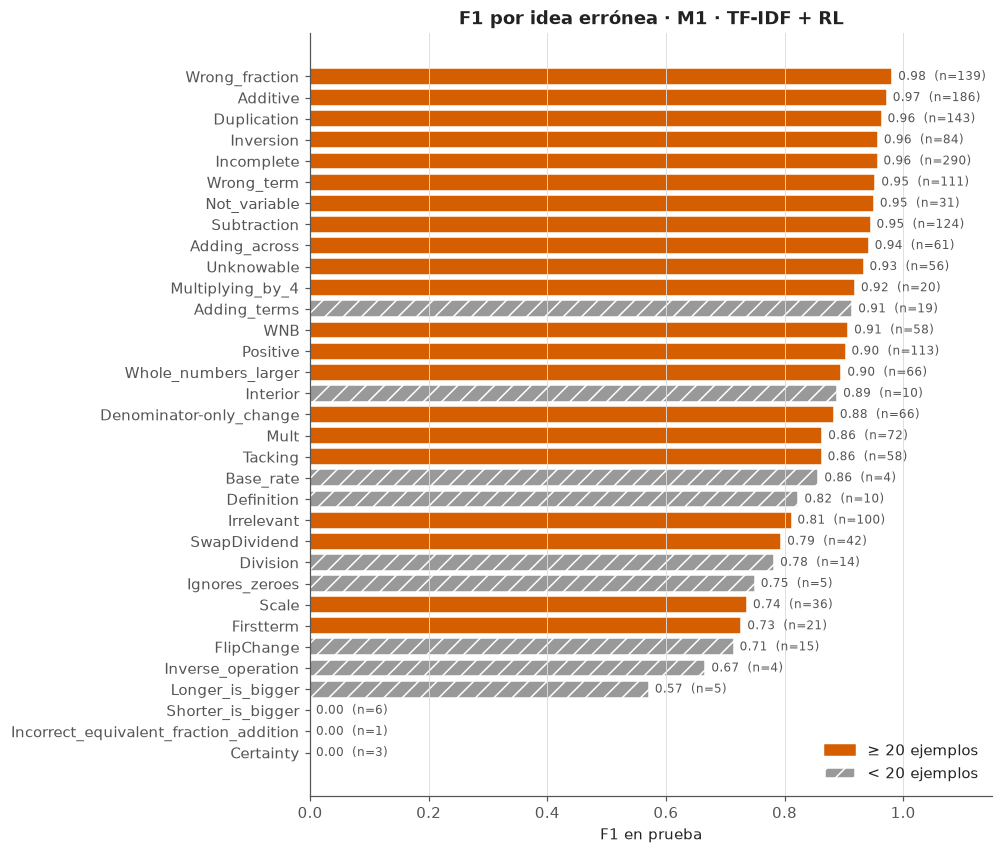

In [11]:
UMBRAL_POCOS = 20
mis = por_clase[(por_clase.nivel == "misconception") & (por_clase.modelo == MEJOR)].sort_values("f1")
pocos = mis["soporte"] < UMBRAL_POCOS

fig, ax = plt.subplots(figsize=(8, 9))
barras = ax.barh(mis["clase"], mis["f1"], color=np.where(pocos, paleta.COLORES_TIPO["Neither"],
                                                         paleta.COLORES_TIPO["Misconception"]),
                 hatch=None, edgecolor="white")
for b, poco in zip(barras, pocos):
    if poco:
        b.set_hatch("//")
for y_, (f1, n) in enumerate(zip(mis["f1"], mis["soporte"])):
    ax.text(f1 + 0.01, y_, f"{f1:.2f}  (n={n})", va="center", fontsize=8, color=paleta.NEUTROS["texto_suave"])
ax.set_xlim(0, 1.15)
ax.set_xlabel("F1 en prueba")
ax.set_title(f"F1 por idea errónea · {paleta.nombre_modelo(MEJOR)}")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=paleta.COLORES_TIPO["Misconception"], label=f"≥ {UMBRAL_POCOS} ejemplos"),
                   Patch(facecolor=paleta.COLORES_TIPO["Neither"], hatch="//", edgecolor="white",
                         label=f"< {UMBRAL_POCOS} ejemplos")], loc="lower right")
fig.savefig(DIR_FIGURAS / "fig3_f1_por_misconception.png")
plt.show()

**Conclusión:** con 20 o más ejemplos, casi todas las ideas erróneas superan F1 0.85; las más difíciles son `Firstterm`, `Scale`, `SwapDividend` e `Irrelevant` (≈ 0.73–0.81), y `Irrelevant` es por definición una categoría heterogénea. Los F1 de 0 aparecen solo en clases con 1 a 6 ejemplos en prueba (`Certainty`, `Shorter_is_bigger`, `Incorrect_equivalent_fraction_addition`), lo que confirma que el desbalance es el principal límite del macro-F1.

### Figura 4. Rendimiento contra tiempo de inferencia

Eje horizontal en escala logarítmica: tiempo para clasificar las 7,340 respuestas de prueba en CPU. El área de cada punto es proporcional al tiempo de entrenamiento.

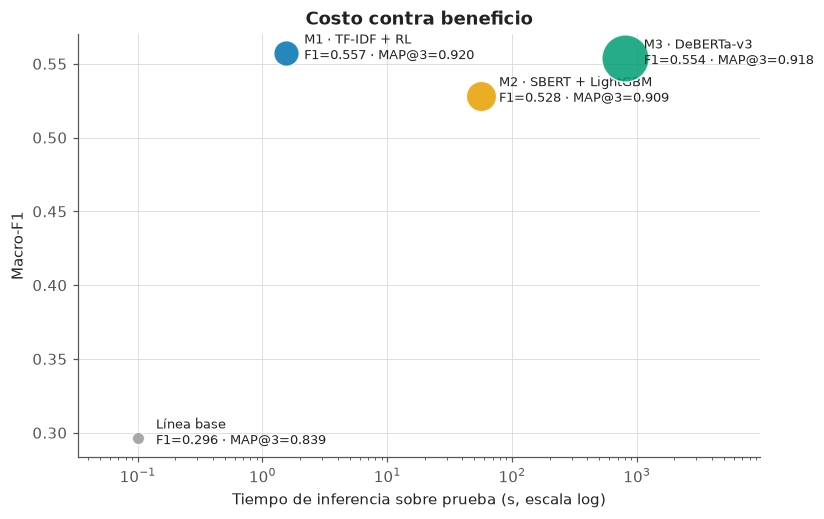

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
t_train = resumen.loc[MODELOS, "tiempo_entrenamiento_s"]
tamanos = 60 + 900 * np.sqrt(t_train / t_train.max())
for m, s in zip(MODELOS, tamanos):
    x, y_ = resumen.loc[m, "tiempo_inferencia_test_s"], resumen.loc[m, "f1_macro"]
    ax.scatter(x, y_, s=s, color=paleta.color_modelo(m), alpha=0.85, edgecolor="white", zorder=3)
    ax.annotate(f"{paleta.nombre_modelo(m)}\nF1={y_:.3f} · MAP@3={resumen.loc[m, 'map_at_3']:.3f}",
                (x, y_), textcoords="offset points", xytext=(12, -4), fontsize=8.5)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de inferencia sobre prueba (s, escala log)")
ax.set_ylabel("Macro-F1")
ax.set_title("Costo contra beneficio")
ax.set_xlim(resumen["tiempo_inferencia_test_s"].min() / 3, resumen["tiempo_inferencia_test_s"].max() * 12)
fig.savefig(DIR_FIGURAS / "fig4_rendimiento_vs_tiempo.png")
plt.show()

**Conclusión:** M1 domina la relación costo-beneficio: el mismo macro-F1 que M3 con ~500 veces menos tiempo de inferencia y ~17 veces menos tiempo de entrenamiento. M2 tiene un costo intermedio pero rinde menos que ambos, así que no está en la frontera eficiente. El costo de M3 (GPU para entrenar, ~0.1 s por respuesta en CPU) no se justifica con estos resultados, salvo que importe su ventaja en la idea errónea concreta.

### Figura 5. Macro-F1 por pregunta y modelo

Cada pregunta tiene su propio conjunto de etiquetas posibles, así que el macro-F1 se calcula dentro de cada pregunta. Las filas están ordenadas por la dificultad promedio.

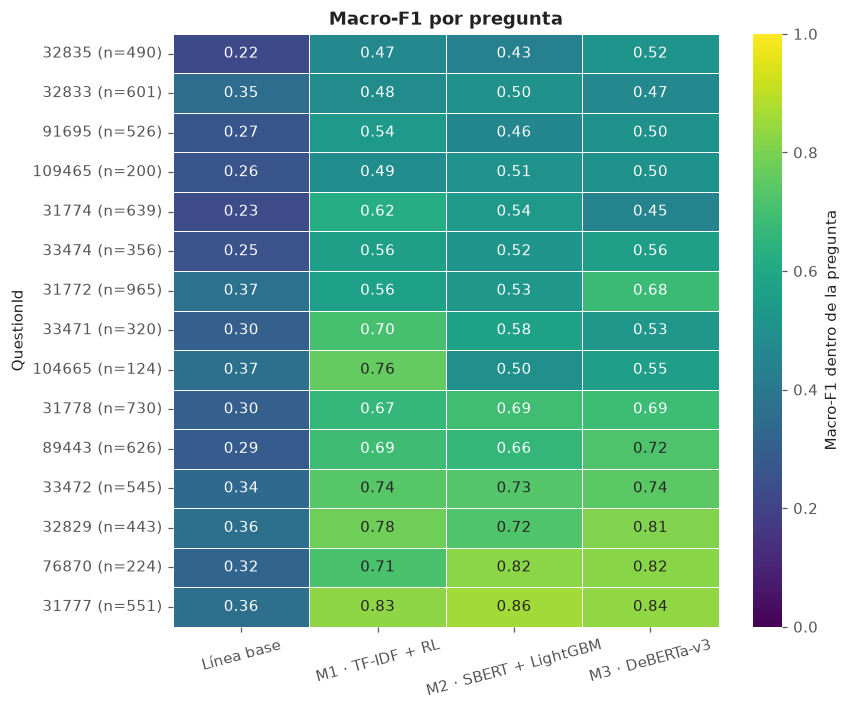

In [13]:
mapa = por_pregunta.pivot(index="QuestionId", columns="modelo", values="f1_macro")[MODELOS]
mapa = mapa.loc[mapa.drop(columns="linea_base").mean(axis=1).sort_values().index]
n_preg = por_pregunta.drop_duplicates("QuestionId").set_index("QuestionId")["n"]
mapa.index = [f"{q} (n={n_preg[q]})" for q in mapa.index]
mapa.columns = [paleta.nombre_modelo(m) for m in mapa.columns]

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(mapa, annot=True, fmt=".2f", cmap=paleta.MAPA_RENDIMIENTO, vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "Macro-F1 dentro de la pregunta"}, linewidths=0.5, linecolor="white")
ax.set_xlabel("")
ax.set_ylabel("QuestionId")
ax.set_title("Macro-F1 por pregunta")
ax.grid(False)
plt.xticks(rotation=15)
fig.savefig(DIR_FIGURAS / "fig5_f1_por_pregunta.png")
plt.show()

**Conclusión:** la dificultad depende más de la pregunta que del modelo: el macro-F1 va de ≈ 0.45–0.55 (32835, 32833, 91695, 109465) a ≈ 0.85 (31777). Ningún modelo gana en todas las preguntas: M3 destaca en 31772 y 32829, M1 en 104665, 33471 y 31774, y M2 en 31777 (y empata con M3 en 76870). Esto confirma el hallazgo del análisis exploratorio sobre la fuerte dependencia de la pregunta, y sugiere que combinar modelos podría ayudar.

### Figura 6. Exactitud según la longitud de la explicación

Relación con el análisis exploratorio, que mostró explicaciones de longitud muy variable (y una bandera `short_explanation` para las de 5 caracteres o menos): ¿la longitud afecta a los modelos?

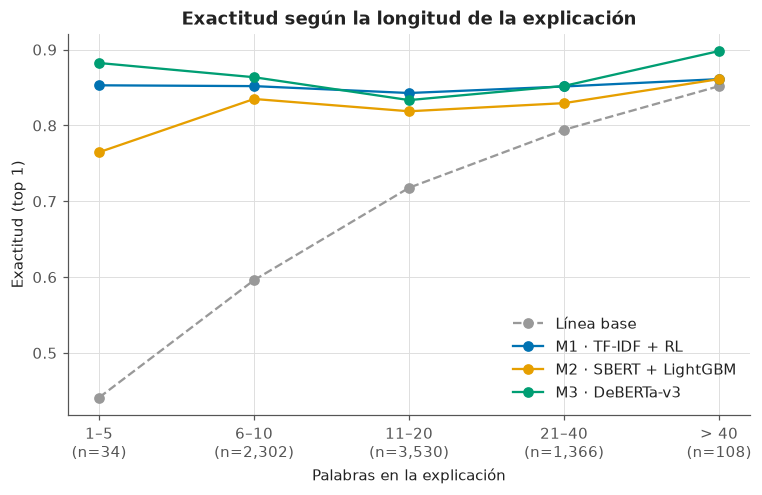

,linea_base,M1_tfidf_lr,M2_sbert_lgbm,M3_deberta
n_palabras,,,,
1–5,0.441,0.853,0.765,0.882
6–10,0.596,0.852,0.835,0.864
11–20,0.718,0.843,0.819,0.833
21–40,0.794,0.851,0.829,0.852
> 40,0.852,0.861,0.861,0.898


In [14]:
cortes = [0, 5, 10, 20, 40, np.inf]
nombres_bin = ["1–5", "6–10", "11–20", "21–40", "> 40"]
filas = []
for m, p in preds.items():
    tramo = pd.cut(p["n_palabras"], cortes, labels=nombres_bin)
    acierto = (p["top1"] == p["target"])
    filas.append(acierto.groupby(tramo, observed=False).mean().rename(m))
por_long = pd.concat(filas, axis=1)
n_tramo = pd.cut(test["n_palabras"], cortes, labels=nombres_bin).value_counts().reindex(nombres_bin)

fig, ax = plt.subplots(figsize=(8, 4.5))
for m in MODELOS:
    ax.plot(range(len(nombres_bin)), por_long[m], marker="o", color=paleta.color_modelo(m),
            label=paleta.nombre_modelo(m), ls="--" if m == "linea_base" else "-")
ax.set_xticks(range(len(nombres_bin)), [f"{b}\n(n={n_tramo[b]:,})" for b in nombres_bin])
ax.set_xlabel("Palabras en la explicación")
ax.set_ylabel("Exactitud (top 1)")
ax.set_title("Exactitud según la longitud de la explicación")
ax.legend(loc="lower right")
fig.savefig(DIR_FIGURAS / "fig6_exactitud_por_longitud.png")
plt.show()
por_long.round(3)

**Conclusión:** la exactitud de los modelos casi no depende de la longitud (≈ 0.82–0.90), pero la de la línea base cae de 0.85 a 0.44 en las explicaciones más cortas. Las explicaciones cortas suelen ser `Neither` aunque el par pregunta-respuesta sugiera otra cosa, así que **es ahí donde leer el texto aporta más**. M2 es el más débil con 1–5 palabras (0.76): el embedding de una frase muy corta tiene poca información. M3 es el mejor con explicaciones largas (> 40 palabras, 0.90), donde su capacidad de contexto pesa más.

## 6. Análisis de errores
### 6.1 Confusiones más frecuentes (etiqueta conjunta, mejor modelo)

In [15]:
p = preds[MEJOR]
err = p[p["top1"] != p["target"]]
print(f"{len(err):,} errores de {len(p):,} ({len(err) / len(p):.1%}); "
      f"en {(err['target'] == err['top2']).mean():.1%} de ellos la etiqueta real es la segunda opción")
conf = err.groupby(["target", "top1"]).size().rename("n").reset_index().sort_values("n", ascending=False)
conf["% de los errores"] = (conf["n"] / len(err) * 100).round(1)
conf.head(12)

1,119 errores de 7,340 (15.2%); en 90.4% de ellos la etiqueta real es la segunda opción


,target,top1,n,% de los errores
98,True_Neither:NA,True_Correct:NA,329,29.4
79,True_Correct:NA,True_Neither:NA,231,20.6
70,False_Neither:NA,False_Misconception:Subtraction,32,2.9
60,False_Neither:NA,False_Misconception:Incomplete,32,2.9
77,False_Neither:NA,False_Misconception:Wrong_term,26,2.3
68,False_Neither:NA,False_Misconception:Positive,23,2.1
24,False_Misconception:Incomplete,False_Neither:NA,22,2.0
35,False_Misconception:Positive,False_Neither:NA,20,1.8
4,False_Correct:NA,False_Neither:NA,18,1.6
29,False_Misconception:Irrelevant,False_Neither:NA,18,1.6


In [16]:
# ¿El error está en la corrección, en el tipo de explicación o solo en la idea errónea?
real, pred_ = ev.descomponer(err["target"]), ev.descomponer(err["top1"])
tipo = np.select(
    [real["correccion"] != pred_["correccion"],
     real["category"] != pred_["category"]],
    ["corrección (True/False)", "tipo de explicación (Correct / Neither / Misconception)"],
    default="solo la idea errónea",
)
pd.Series(tipo).value_counts(normalize=True).mul(100).round(1).rename("% de los errores")

tipo de explicación (Correct / Neither / Misconception)    97.9
solo la idea errónea                                        2.1
Name: % de los errores, dtype: float64

**Conclusión:** casi todos los errores (98 %) están en el **tipo de explicación** (Correct / Neither / Misconception), y la mitad son solo el intercambio `True_Neither` ↔ `True_Correct`. Cuando el modelo reconoce que hay una idea errónea, casi siempre elige la correcta (solo 2 % de los errores). Además, en 90 % de los errores la etiqueta real es la segunda opción, lo que explica el MAP@3 alto.

### 6.2 Ejemplos reales de errores

In [17]:
cols = ["QuestionId", "MC_Answer_norm", "StudentExplanation", "target", "top1", "prob1"]
with pd.option_context("display.max_colwidth", 120):
    display(err.sort_values("prob1", ascending=False)[cols].head(5))   # errores con mucha confianza
    display(err[err["target"].str.contains("Misconception")].sample(5, random_state=42)[cols])

,QuestionId,MC_Answer_norm,StudentExplanation,target,top1,prob1
2652,31778,6,I think this because 9/15 as a 1/5 is 3/5. Therefore 3/5 a 1/10 is 6/10.,True_Neither:NA,True_Correct:NA,0.9996
1818,31777,72,120 divded by 5 is ...,True_Neither:NA,True_Correct:NA,0.9996
2982,32829,12,"because to get to 24 from 2, you would do 24x2= 12. that is why i think it is 12.",True_Neither:NA,True_Correct:NA,0.9996
2116,31777,72,i divided 120 by 5 which is 60 and 60 times 3 is 72,True_Neither:NA,True_Correct:NA,0.9996
3852,32833,2/15,b because when you have 2 times 5 the denominator is only 4 so it comes out to be 1 2/5 which is howw close we got t...,False_Neither:NA,False_Misconception:Inversion,0.9987


,QuestionId,MC_Answer_norm,StudentExplanation,target,top1,prob1
1016,31774,3,I think this because 1/2= divide 2 and divided by 6 and got 3,False_Misconception:SwapDividend,False_Misconception:FlipChange,0.8015
4021,32835,6,"it has no tenths nor hundreths, therefore it is the largest",False_Misconception:Whole_numbers_larger,False_Neither:NA,0.9399
5719,76870,Not enough information,you dont know the sum of all the angles,False_Misconception:Unknowable,False_Neither:NA,0.7279
3914,32833,2/15,the answer is 10 becausee 2x5=10 and 5x3 =15.,False_Misconception:Duplication,False_Neither:NA,0.5812
6092,89443,-3,"When you take out negativee numbers the result is always positive, so if you have -8 and take off -5 you will have 3...",True_Misconception:Tacking,True_Neither:NA,0.5718


**Conclusión:** los errores con mucha confianza muestran el límite de un modelo léxico: *"i divided 120 by 5 which is 60 and 60 times 3 is 72"* tiene las palabras de una explicación correcta, pero 120 / 5 no es 60, y el anotador la marcó como `Neither`. El modelo **no verifica la aritmética**. Otros casos son explicaciones incompletas o ambiguas, donde incluso la etiqueta es discutible. En las ideas erróneas falladas, el modelo suele predecir `Neither`, es decir, no detecta el patrón erróneo cuando el estudiante lo expresa con palabras poco usuales.

### 6.3 Coincidencia entre modelos

Si los modelos se equivocan en filas distintas, una combinación podría mejorar el resultado.

In [18]:
aciertos = pd.DataFrame({m: (preds[m]["top1"] == preds[m]["target"]).values for m in MODELOS if m != "linea_base"})
print(f"Al menos un modelo acierta: {aciertos.any(axis=1).mean():.1%}")
print(f"Todos aciertan:             {aciertos.all(axis=1).mean():.1%}")
print(f"Ninguno acierta:            {(~aciertos.any(axis=1)).mean():.1%}")
pd.DataFrame({a: {b: (aciertos[a] == aciertos[b]).mean() for b in aciertos} for a in aciertos}).round(3)

Al menos un modelo acierta: 92.8%
Todos aciertan:             73.6%
Ninguno acierta:            7.2%


,M1_tfidf_lr,M2_sbert_lgbm,M3_deberta
M1_tfidf_lr,1.000,0.865,0.873
M2_sbert_lgbm,0.865,1.000,0.877
M3_deberta,0.873,0.877,1.000


**Conclusión:** el mejor modelo acierta el 84.8 %, pero al menos uno de los tres acierta el 92.8 %, y solo el 7.2 % de las respuestas las fallan todos. Los modelos coinciden en ~87 % de las filas, así que se equivocan en filas en parte distintas: **combinar sus probabilidades** (por ejemplo, promediar M1 y M3) es la mejora más directa para un trabajo futuro.